In [1]:
# Import modules
import os
import sys

# Make sure that the executable path exists in the environment path
env_bin = os.path.dirname(sys.executable)
if env_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{env_bin}:{os.environ['PATH']}"

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
import dask
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import scipy.signal as signal
import xarray as xr
import yaml
from IPython.display import display

with open("config.yml") as f:
    config = yaml.safe_load(f)
viz_opts = config["viz"]

ERROR 1: PROJ: proj_create_from_database: Open of /albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/share/proj failed


In [2]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=4, threads_per_worker=4)
client = Client(cluster)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 8.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45831,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33823,Total threads: 4
Dashboard: http://127.0.0.1:42053/status,Memory: 2.00 GiB
Nanny: tcp://127.0.0.1:38311,


# Define Helper Functions

In [3]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-60, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    lathelp = np.arange(-75, -60, 5)
    gl.ylocator = mticker.FixedLocator(lathelp)
    lonhelp = np.arange(-80, -10, 10)
    gl.xlocator = mticker.FixedLocator(lonhelp)

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

# Load ERA5 Data

In [4]:
# wind = xr.open_dataset("./data/era5_winddata.grib", engine="cfgrib", chunks='auto')
wind = xr.open_dataset(
    "./data/era5_winddata.grib",
    engine="cfgrib",
    chunks={"time": 1000, "latitude": 200, "longitude": 200},
)

In [5]:
wind

<xarray.Dataset> Size: 4GB
Dimensions:        (time: 13140, latitude: 161, longitude: 221)
Coordinates:
  * time           (time) datetime64[ns] 105kB 2017-01-01 ... 2019-12-31T22:0...
    valid_time     (time) datetime64[ns] 105kB dask.array<chunksize=(1000,), meta=np.ndarray>
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Data variables:
    u              (time, latitude, longitude) float32 2GB dask.array<chunksize=(1000, 161, 200), meta=np.ndarray>
    v              (time, latitude, longitude) float32 2GB dask.array<chunksize=(1000, 161, 200), meta=np.ndarray>
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-05-06T14:31 GRIB to CDM+CF via cfgrib-0.9.1...

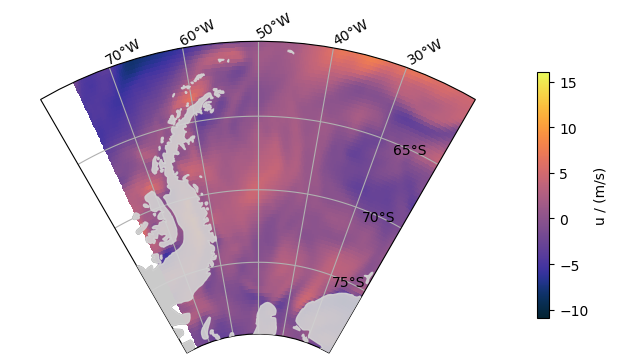

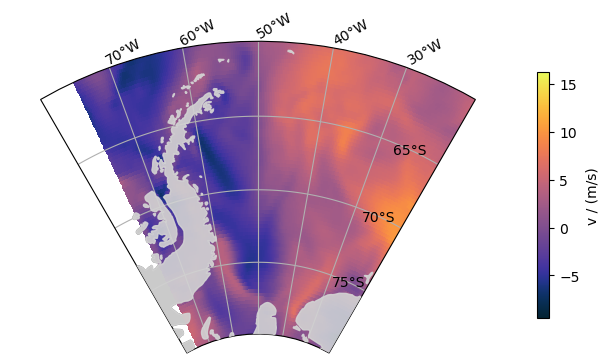

In [6]:
lat = wind.variables["latitude"][:]  # latitude grid points
lon = wind.variables["longitude"][:]  # longitude grid points

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon, lat, wind.isel(time=0).variables["u"], transform=ccrs.PlateCarree(), cmap=cm.cm.thermal
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="u / (m/s)")
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon, lat, wind.isel(time=0).variables["v"], transform=ccrs.PlateCarree(), cmap=cm.cm.thermal
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="v / (m/s)");

# Extract time series at mooring sites

In [7]:
# boxlats = np.array([mooring.location.lat+height_in_lat/2,mooring.location.lat-height_in_lat/2])
# boxlons = np.array([mooring.location.lon-width_in_lon/2,mooring.location.lon+width_in_lon/2])

moorings = {
    "A": {"lat": -63.4032, "lon": -52.287},
    "B": {"lat": -63.5145, "lon": -51.6357},
    "C": {"lat": -63.656, "lon": -50.8113},
    "D": {"lat": -63.7783, "lon": -50.0897},
    "E": {"lat": -63.917, "lon": -49.2682},
    "F": {"lat": -64.0665, "lon": -48.3805},
    "G": {"lat": -64.2157, "lon": -47.4903},
}

mooring_names = moorings.keys()
width_in_lon = 1
height_in_lat = 0.5

# mooring_boxes = {}
# for name, mooring in zip(mooring_names, moorings):

#     boxlats = np.array([mooring.location.lat+height_in_lat/2,mooring.location.lat-height_in_lat/2])
#     boxlons = np.array([mooring.location.lon-width_in_lon/2,mooring.location.lon+width_in_lon/2])

#     mooring_bins[name] = {
#         "lat": boxlats,
#         "lon": boxlons
# }

mooring_boxes = {
    "A": {"lat": np.array([-63.1532, -63.6532]), "lon": np.array([-52.787, -51.787])},
    "B": {"lat": np.array([-63.2645, -63.7645]), "lon": np.array([-52.1357, -51.1357])},
    "C": {"lat": np.array([-63.406, -63.906]), "lon": np.array([-51.3113, -50.3113])},
    "D": {"lat": np.array([-63.5283, -64.0283]), "lon": np.array([-50.5897, -49.5897])},
    "E": {"lat": np.array([-63.667, -64.167]), "lon": np.array([-49.7682, -48.7682])},
    "F": {"lat": np.array([-63.8165, -64.3165]), "lon": np.array([-48.8805, -47.8805])},
    "G": {"lat": np.array([-63.9657, -64.4657]), "lon": np.array([-47.9903, -46.9903])},
}

In [8]:
# for name, bounds in mooring_boxes.items():
#     print(name, bounds)

In [9]:
def setup_transect_view(fig):
    ax = fig.add_subplot(111, projection=ccrs.SouthPolarStereo(central_longitude=-50))
    # Limit the map to -60 degrees latitude and below.
    ax.set_extent([-54, -46, -64.5, -62.6], crs=ccrs.PlateCarree())
    # ax.set_extent([-55, -45, -65, -62], ccrs.PlateCarree())
    ax.gridlines(draw_labels=True)
    return ax

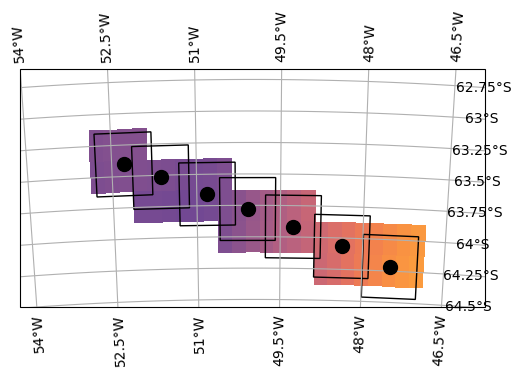

In [10]:
fig = plt.figure(figsize=(6, 6))
ax = setup_transect_view(fig)

ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)

for name, bounds in mooring_boxes.items():
    wind_at_mooring = wind.sel(
        latitude=slice(bounds["lat"][0], bounds["lat"][1]),
        longitude=slice(bounds["lon"][0], bounds["lon"][1]),
    )
    boxlat = wind_at_mooring.variables["latitude"][:]  # latitude grid points
    boxlon = wind_at_mooring.variables["longitude"][:]  # longitude grid points

    assert boxlat.size != 1
    assert boxlon.size != 1

    # Compute monthly statistics averaged over space
    im = ax.pcolormesh(
        boxlon,
        boxlat,
        wind_at_mooring.isel(time=0).variables["v"],
        vmin=-6,
        vmax=8,
        transform=ccrs.PlateCarree(),
        cmap=cm.cm.thermal,
        shading="nearest",
    )

for name, mooring in moorings.items():
    ax.plot(mooring["lon"], mooring["lat"], "k.", ms=20, transform=ccrs.PlateCarree())

for _name, box in mooring_boxes.items():
    patch = mpatches.Rectangle(
        xy=[box["lon"][0], box["lat"][1]],  # lower left corner
        width=width_in_lon,
        height=height_in_lat,
        facecolor="none",
        edgecolor="k",
        transform=ccrs.PlateCarree(),
    )
    # assert np.all(patch.get_center() == (mooring["lon"], mooring["lat"]))
    ax.add_patch(patch)

In [21]:
# Create an empty dictionary to store results
results = {}
for name, bounds in mooring_boxes.items():
    wind_at_mooring = wind.sel(
        latitude=slice(bounds["lat"][0], bounds["lat"][1]),
        longitude=slice(bounds["lon"][0], bounds["lon"][1]),
    )

    # complex_wind = wind_at_mooring.assign(wind = wind_at_mooring.u + 1j * wind_at_mooring.v)
    # Compute monthly statistics averaged over space
    wind_mean = (wind_at_mooring.mean(dim=["latitude", "longitude"])).chunk({"time": 1000})
    wind_std = (wind_at_mooring.std(dim=["latitude", "longitude"])).chunk({"time": 1000})

    results[name] = {"mean": wind_mean, "std": wind_std}

In [26]:
results["A"]["mean"]["u"]  # .data.dask.visualize(**viz_opts)

<xarray.DataArray 'u' (time: 13140)> Size: 53kB
dask.array<mean_agg-aggregate, shape=(13140,), dtype=float32, chunksize=(1000,), chunktype=numpy.ndarray>
Coordinates:
  * time           (time) datetime64[ns] 105kB 2017-01-01 ... 2019-12-31T22:0...
    valid_time     (time) datetime64[ns] 105kB dask.array<chunksize=(1000,), meta=np.ndarray>
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             131
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      35581
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           u
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    long_name:                                U component of wind
    units:                                    m s**-1
    standard_name:                            eastward_wind

In [13]:
mean_wind_df = pd.DataFrame(index=wind_mean["time"])
std_wind_df = pd.DataFrame(index=wind_std.variables["time"].values)
for name, result in results.items():
    mean_wind_df[name] = (result["mean"].variables["u"] + 1j * result["mean"].variables["v"]).load()
    std_wind_df[name] = (result["std"].variables["u"] + 1j * result["std"].variables["v"]).load()

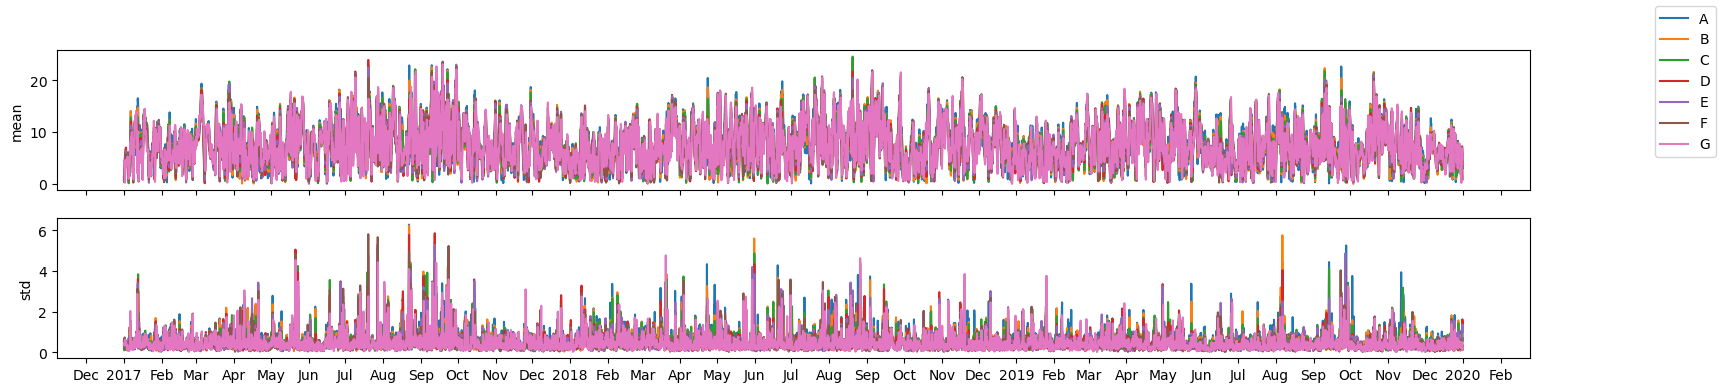

In [17]:
fig, ax = plt.subplots(nrows=2, figsize=(19, 4), sharex=True)
for col in mean_wind_df.columns:
    ax[0].plot(mean_wind_df.index, mean_wind_df[col].abs(), label=col)
    ax[1].plot(std_wind_df.index, std_wind_df[col].abs())  # , label = col)
fig.legend()
ax[0].set_ylabel("mean")
ax[1].set_ylabel("std")
locator = mdates.AutoDateLocator(minticks=5, maxticks=50)
formatter = mdates.ConciseDateFormatter(locator)
ax[1].xaxis.set_major_locator(locator)
ax[1].xaxis.set_major_formatter(formatter)

In [29]:
mean_wind_df

,A,B,C,D,E,F,G
2017-01-01 00:00:00,0.082321-0.779099j,-0.985672-1.117599j,-0.841141-1.157150j,-0.776932-0.163010j,-0.622757+1.181229j,0.361618+2.730423j,0.995529+4.345047j
2017-01-01 02:00:00,-0.352692-1.312180j,-0.907501-1.896896j,-0.661407-1.712448j,-0.664825-0.986618j,-0.528961+0.096024j,0.509491+1.876297j,0.931000+3.682205j
2017-01-01 04:00:00,-0.378357-1.614365j,-0.449036-2.029160j,-0.421326-1.749374j,-0.197327-1.257309j,0.147278-0.381943j,1.002502+1.557266j,1.150940+3.468155j
2017-01-01 06:00:00,-0.263062-1.986130j,-0.333130-2.073044j,-0.473389-1.825974j,-0.104126-1.374802j,0.354858-0.401291j,1.225464+1.456131j,1.200684+3.333328j
2017-01-01 08:00:00,-0.131668-2.211472j,-0.265945-2.241867j,-0.521561-2.077072j,-0.434525-1.548019j,-0.039871-0.386032j,1.039108+1.494461j,1.017136+3.294876j
...,...,...,...,...,...,...,...
2019-12-31 14:00:00,5.182266-2.615738j,3.906876-2.183731j,2.177383-2.536148j,-1.633652-4.346695j,-3.365707-4.923843j,-4.535873-5.675552j,-4.260483-5.467056j
2019-12-31 16:00:00,5.890701-1.233780j,4.646805-0.793350j,3.303421-1.020401j,-0.731125-3.273575j,-2.957321-4.105972j,-4.505173-5.183731j,-4.174850-5.490616j
2019-12-31 18:00:00,5.124466+0.430511j,3.926346+0.044281j,3.110428+0.010834j,0.305374-2.027496j,-2.400436-3.324860j,-4.580002-4.672150j,-4.104050-5.052032j
2019-12-31 20:00:00,4.556122+1.953903j,3.935150+0.866745j,2.883636+0.381516j,-0.173126-1.219803j,-2.132355-2.597488j,-3.990631-4.285721j,-3.910431-4.365799j


# Filter to wind at inertial frequencies

In [35]:
def get_coriolis_frequency(lat, unit="rad/s", absolute=False):

    if absolute:
        lat = abs(lat)

    Omega = 7.2921 * 1e-5  # unit: rad/s

    f = 2 * Omega * np.sin(lat * np.pi / 180.0)

    if unit == "rad/s":
        return f

    if unit == "Hz":
        return f / (2 * np.pi)

    if unit == "cpd":
        return f / (2 * np.pi) * 3600 * 24

    raise NotImplementedError("Specified unit is not implemented")

In [38]:
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    """
    # Sample rate and desired cutoff frequencies (in Hz).
    fs = 1/7200 #sampling period of 2 hours
    lowcut = 1/(14*60*60) #period of 18 hours
    highcut = 1/(10*60*60) #period of 10 hours
    filtered_u = butter_bandpass_filter(patched_u, lowcut, highcut, fs, order=6)
    filtered_v = butter_bandpass_filter(patched_v, lowcut, highcut, fs, order=6)
    """
    # from scipy.signal import lfilter
    # b, a = Data.butter_bandpass(lowcut, highcut, fs, order=order)
    # y = lfilter(b, a, data)

    # use of second-order sections (sos) as recommended in https://docs.scipy.org/doc/scipy-1.14.1/reference/generated/scipy.signal.butter.html
    sos = signal.butter(order, [lowcut, highcut], "bandpass", fs=fs, output="sos")
    # use filtfilt with 2 filtering passes to prevent an artificial phase shift
    filtered = signal.sosfiltfilt(sos, data)

    return filtered

In [41]:
mean_wind_around_f = pd.DataFrame(index=mean_wind_df.index)

mean_lat = -64
f_in_Hz = get_coriolis_frequency(lat=mean_lat, unit="Hz", absolute=True)
f_in_cpd = get_coriolis_frequency(lat=mean_lat, unit="cpd", absolute=True)
print(f_in_Hz, f_in_cpd)

2.08623357249356e-05 1.8025058066344357


In [63]:
lowcut = f_in_Hz * 0.9
highcut = f_in_Hz * 1.1
two_hour_period = 1 / 7200
for name, series in mean_wind_df.items():
    mean_wind_around_f[name] = butter_bandpass_filter(
        series, lowcut, highcut, fs=two_hour_period, order=5
    )

In [64]:
mean_wind_around_f

,A,B,C,D,E,F,G
2017-01-01 00:00:00,-0.007649+0.007186j,0.008048+0.010989j,-0.006696+0.001670j,-0.011086-0.018529j,0.010334-0.016611j,0.055606+0.003771j,0.055453+0.009419j
2017-01-01 02:00:00,0.200140+0.099254j,0.288184+0.015165j,0.238438+0.058750j,0.236227+0.033880j,0.215830-0.042397j,0.193863-0.060977j,0.215418-0.020897j
2017-01-01 04:00:00,0.227038+0.118374j,0.320034+0.013580j,0.281288+0.078073j,0.282565+0.072403j,0.231092-0.022674j,0.157297-0.072902j,0.189595-0.027499j
2017-01-01 06:00:00,0.055178+0.046116j,0.080404+0.000799j,0.088689+0.039532j,0.096756+0.065551j,0.051712+0.025941j,-0.023625-0.026878j,-0.007445-0.012583j
2017-01-01 08:00:00,-0.160052-0.066992j,-0.222799-0.020798j,-0.174033-0.034705j,-0.160180+0.007478j,-0.161664+0.053357j,-0.186046+0.034914j,-0.206231+0.003853j
...,...,...,...,...,...,...,...
2019-12-31 14:00:00,-0.180528+0.032014j,-0.151632+0.012731j,-0.158708-0.025752j,-0.148245+0.009188j,-0.117879+0.059258j,-0.102565+0.054031j,-0.157787+0.016445j
2019-12-31 16:00:00,-0.046602+0.003736j,-0.068646+0.048817j,-0.074478+0.054305j,-0.039970+0.072022j,-0.044200+0.094074j,-0.090083+0.102209j,-0.165202+0.024736j
2019-12-31 18:00:00,0.104199-0.031043j,0.057644+0.038451j,0.058464+0.080030j,0.091503+0.068881j,0.060750+0.049127j,-0.002845+0.064137j,-0.037185+0.010011j
2019-12-31 20:00:00,0.156929-0.041681j,0.123384-0.002485j,0.128636+0.039221j,0.135554+0.014061j,0.106608-0.025473j,0.079004-0.014823j,0.106483-0.006950j


In [65]:
def smooth(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    # smooth by convolving speed with window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(window)
    return smoothed

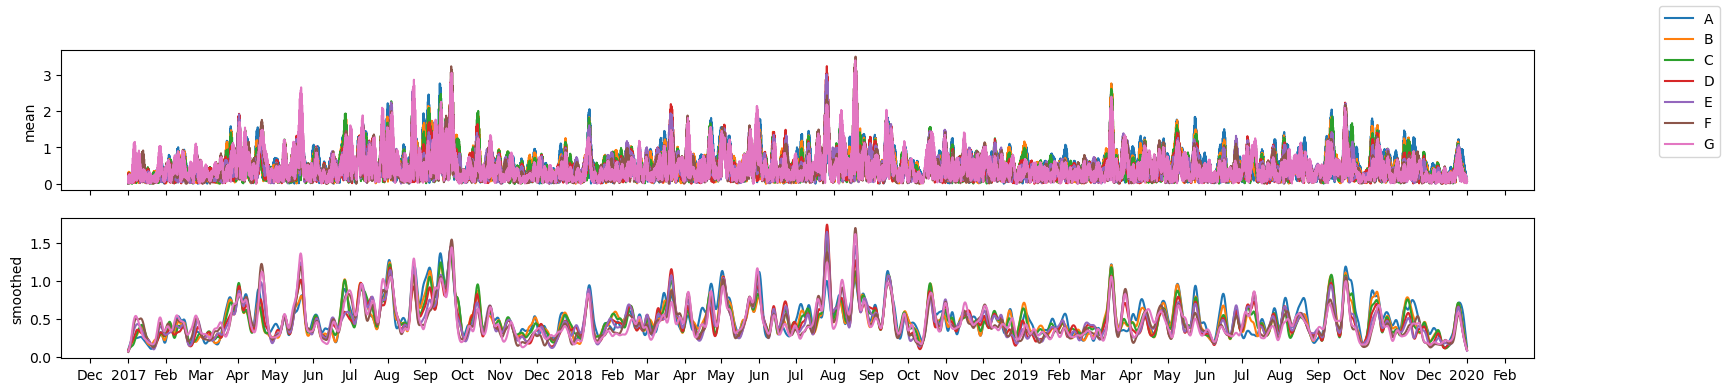

In [66]:
fig, ax = plt.subplots(nrows=2, figsize=(19, 4), sharex=True)
for col in mean_wind_df.columns:
    ax[0].plot(mean_wind_around_f.index, mean_wind_around_f[col].abs(), label=col)
    ax[1].plot(mean_wind_around_f.index, smooth(mean_wind_around_f[col].abs(), 100))
fig.legend()
ax[0].set_ylabel("mean")
ax[1].set_ylabel("smoothed")
locator = mdates.AutoDateLocator(minticks=5, maxticks=50)
formatter = mdates.ConciseDateFormatter(locator)
ax[1].xaxis.set_major_locator(locator)
ax[1].xaxis.set_major_formatter(formatter)

In [67]:
mean_wind_around_f.to_csv("./inertial_wind.csv")